In [1]:
from ccvtools import rawio
import imageio.v2 as iio
import numpy as np
from tqdm import tqdm

%matplotlib ipympl
import matplotlib.pyplot as plt 

In [2]:
files = [
    "D:/yamlsaving/pylon1.ccv",
    "E:/yamlsaving/pylon2.ccv",
    "F:/yamlsaving/pylon3.ccv",
]

In [3]:
framerate = 100

In [4]:
readers = [iio.get_reader(file) for file in files]
print("Number of frames: ", [len(r) for r in readers])

Number of frames:  [1151, 1151, 1151]


In [5]:
# Read all timestamps from video files for further analysis
timestamps_all = []
fr_idxs_all = []
for i_c, r in enumerate(readers):
    timestamps = []
    fr_idxs = []
    for i_f in range(len(r)):
        md = readers[i_c].get_meta_data(i_f)
        timestamps.append(md["timestamp"])
        fr_idxs.append(md["index"])
    timestamps_all.append(np.array(timestamps))
    fr_idxs_all.append(np.array(fr_idxs))

==== Cam 0 ====
Maximum step in frame idx:  1
Maximum and minimum local fps:  99.99713008325035 99.99659011605033
Number of frames with local fps < 75/s 0
==== Cam 1 ====
Maximum step in frame idx:  1
Maximum and minimum local fps:  99.9976700562819 99.99632013350032
Number of frames with local fps < 75/s 0
==== Cam 2 ====
Maximum step in frame idx:  1
Maximum and minimum local fps:  99.99821003287141 99.9968600977846
Number of frames with local fps < 75/s 0


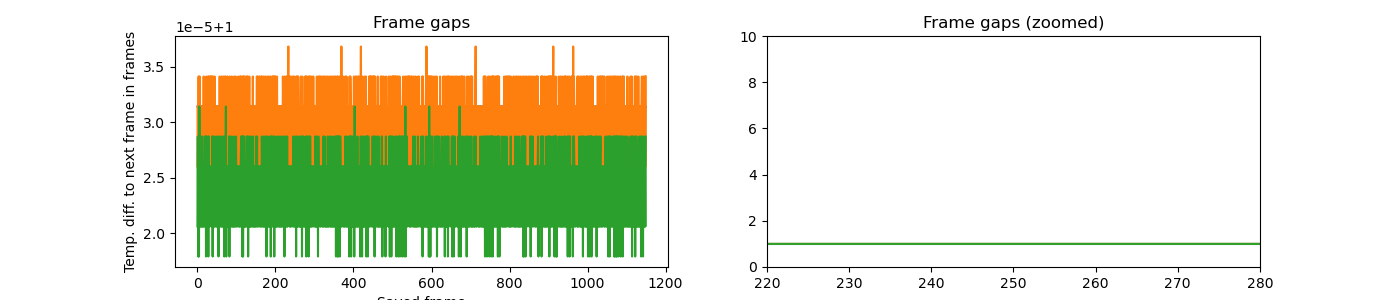

In [6]:
# Plot gaps between frames based on camera times
fig, axs = plt.subplots(1,2, figsize=(14,3))
for i_id, (ids, ts) in enumerate(zip(fr_idxs_all, timestamps_all)):
    print(f"==== Cam {i_id} ====")
    print("Maximum step in frame idx: ", np.max(np.diff(ids)))
    print("Maximum and minimum local fps: ", 1/np.min(np.diff(ts)), 1/np.max(np.diff(ts)))
    print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))
    axs[0].plot(np.diff(ts)*framerate)
    axs[0].set_title("Frame gaps")
    axs[0].set_xlabel("Saved frame")
    axs[0].set_ylabel("Temp. diff. to next frame in frames")
    axs[1].plot(np.diff(ts)*framerate)
    axs[1].set_xlim((220,280))
    axs[1].set_ylim((0,10))
    axs[1].set_title("Frame gaps (zoomed)")
    axs[0].set_xlabel("Saved frame")

In [7]:
# Print first 10 saved frame idxs and cam times
for i_cam in range(len(files)):
    print("Cam ", i_cam)
    timestamps = []
    for i in range(10):
        md = readers[i_cam].get_meta_data(i)
        print(md)
        timestamps.append(md["timestamp"])
    timestamps = np.array(timestamps)
    print(np.diff(timestamps)/(1/framerate))

Cam  0
{'index': 1, 'timestamp': 1232.375665131}
{'index': 2, 'timestamp': 1232.385665445}
{'index': 3, 'timestamp': 1232.395665759}
{'index': 4, 'timestamp': 1232.405666073}
{'index': 5, 'timestamp': 1232.41566636}
{'index': 6, 'timestamp': 1232.425666674}
{'index': 7, 'timestamp': 1232.435666988}
{'index': 8, 'timestamp': 1232.445667275}
{'index': 9, 'timestamp': 1232.455667589}
{'index': 10, 'timestamp': 1232.465667903}
[1.0000314 1.0000314 1.0000314 1.0000287 1.0000314 1.0000314 1.0000287
 1.0000314 1.0000314]
Cam  1
{'index': 1, 'timestamp': 1233.508174326}
{'index': 2, 'timestamp': 1233.518174586}
{'index': 3, 'timestamp': 1233.5281749}
{'index': 4, 'timestamp': 1233.53817516}
{'index': 5, 'timestamp': 1233.548175501}
{'index': 6, 'timestamp': 1233.558175734}
{'index': 7, 'timestamp': 1233.568176075}
{'index': 8, 'timestamp': 1233.578176416}
{'index': 9, 'timestamp': 1233.588176676}
{'index': 10, 'timestamp': 1233.59817699}
[1.000026  1.0000314 1.000026  1.0000341 1.0000233 1.000

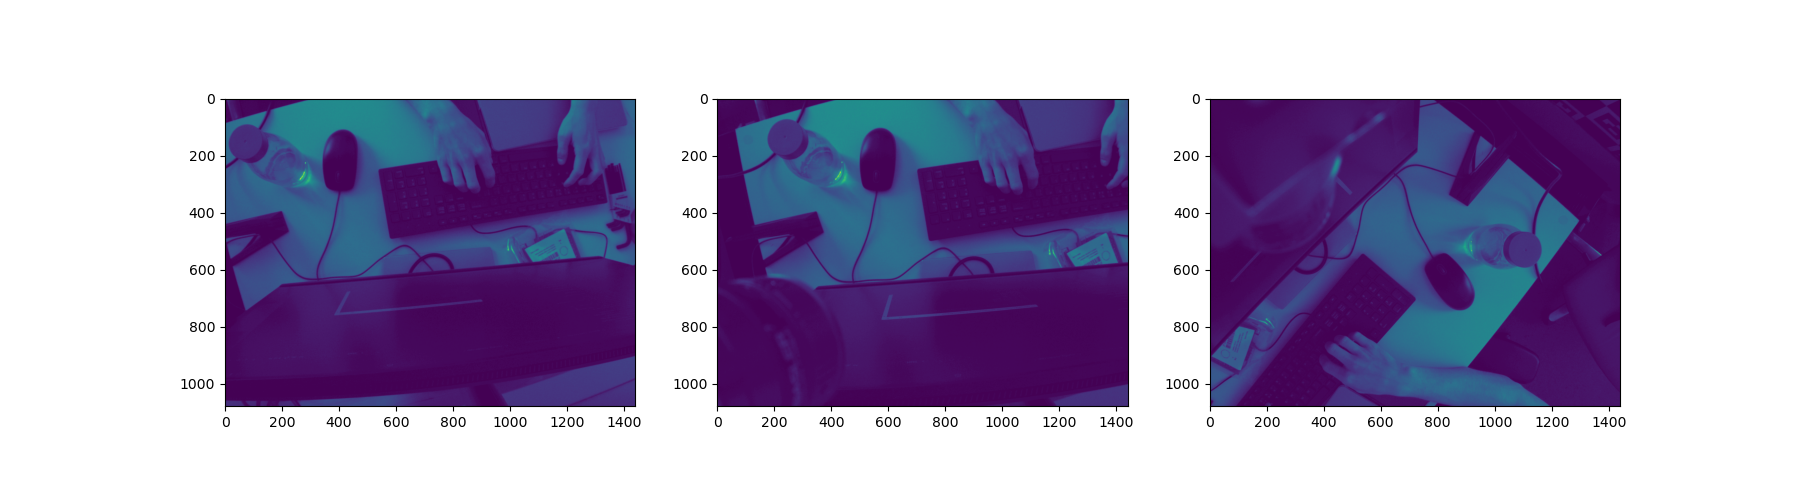

In [8]:
# Plot single frame from each cam
fig, axs = plt.subplots(1,len(files), figsize=(18,5), squeeze=False)
for ax,r in zip(axs[0],readers):
    ax.imshow(r.get_data(230))

In [9]:
# Print local frame rate
1/np.diff(timestamps)

array([99.99794004, 99.99713008, 99.99821003, 99.99713008, 99.99821003,
       99.9968601 , 99.99740007, 99.99794004, 99.99740007])